# E-Commerce Customer Churn Prediction

**Goal:** Predict which customers of an online e-commerce platform are likely to churn (stop using the platform), so the business can target retention efforts (discounts, outreach, support) at the customers most at risk.

**Dataset:** 5,630 customers, 20 features covering tenure, app usage, order behavior, satisfaction, complaints, and payment/marital/city info. Source: [Kaggle — E Commerce Dataset](https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction).

**Approach:**
1. Clean and explore the data
2. Engineer features and encode categoricals
3. Handle class imbalance (only ~17% of customers churn)
4. Train and compare Logistic Regression vs. Random Forest
5. Evaluate with precision/recall/F1/AUC-ROC (accuracy alone is misleading on imbalanced data)
6. Interpret which factors drive churn most

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_numeric_dtype

sns.set_style("whitegrid")
%matplotlib inline

pd.set_option("display.max_columns", None)

## 1. Load & Inspect the Data

In [2]:
df = pd.read_excel('../data/raw/E_Commerce_Dataset.xlsx', sheet_name='E Comm')
print(f"Shape: {df.shape}")
df.head()

Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
print("Duplicate rows:", df.duplicated().sum())
print()
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Duplicate rows: 0

Missing values per column:
Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.50,54222.7500,55630.00
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.00
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.00
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.00
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.00
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.00
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.00
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.00
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.00


No duplicate rows. Several columns have missing values (all numeric), which we'll impute below. `CustomerID` is a unique identifier with no predictive value and will be dropped.

## 2. Data Cleaning

In [5]:
df_clean = df.drop(columns=['CustomerID']).copy()

# Churn and CityTier are categorical codes, not continuous numbers
df_clean['Churn'] = df_clean['Churn'].astype('object')
df_clean['CityTier'] = df_clean['CityTier'].astype('object')

**Bug fix vs. the original exploratory version of this notebook:** a naive `df.fillna(df[col].median())` inside a loop over columns will fill the *entire* dataframe with a single column's median on every iteration, silently corrupting unrelated columns. The correct approach imputes each column with **its own** median:

In [6]:
for col in df_clean.columns:
    if df_clean[col].isnull().sum() > 0 and is_numeric_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

assert df_clean.isnull().sum().sum() == 0, "Missing values remain!"
print("All missing values imputed with per-column medians.")

All missing values imputed with per-column medians.


### Outlier check

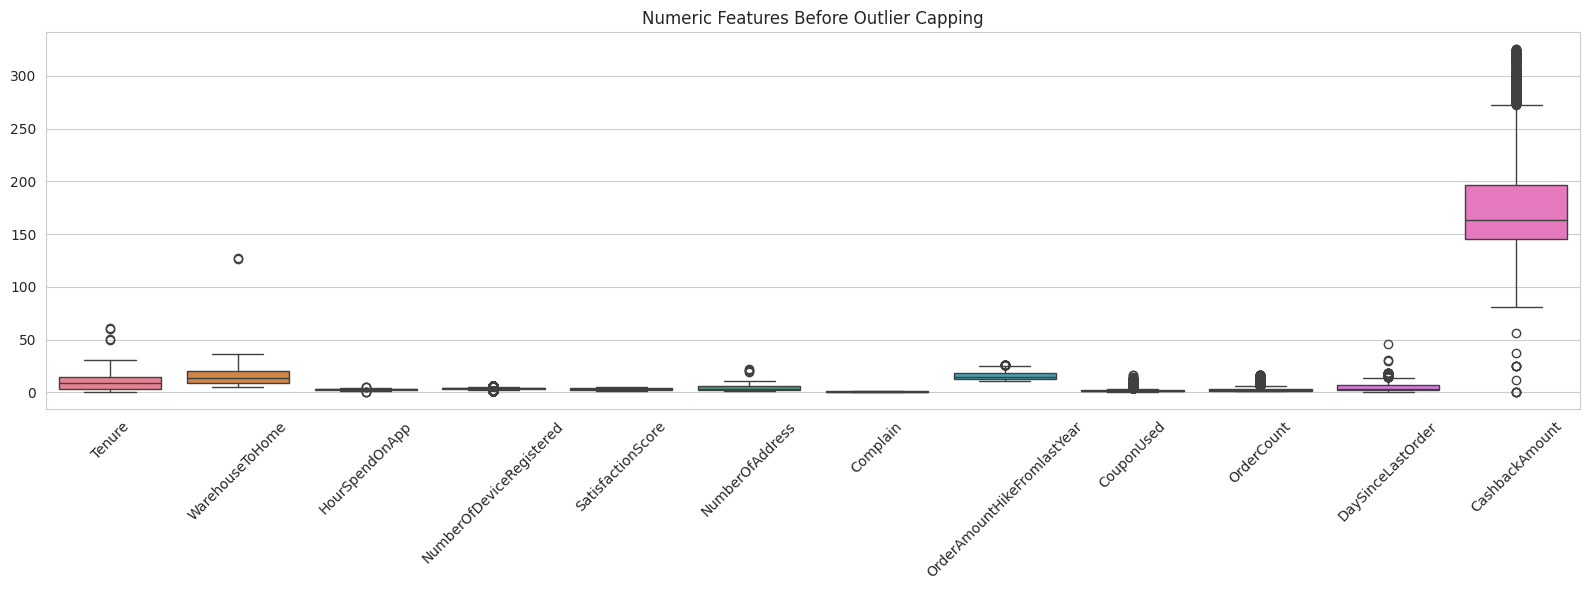

In [7]:
plt.figure(figsize=(16, 6))
sns.boxplot(data=df_clean.select_dtypes(include=['int64', 'float64']))
plt.title('Numeric Features Before Outlier Capping')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Several features (e.g. `WarehouseToHome`, `NumberOfAddress`) have long tails. We cap extreme values using the IQR rule (winsorizing) so a handful of outliers don't dominate the models.

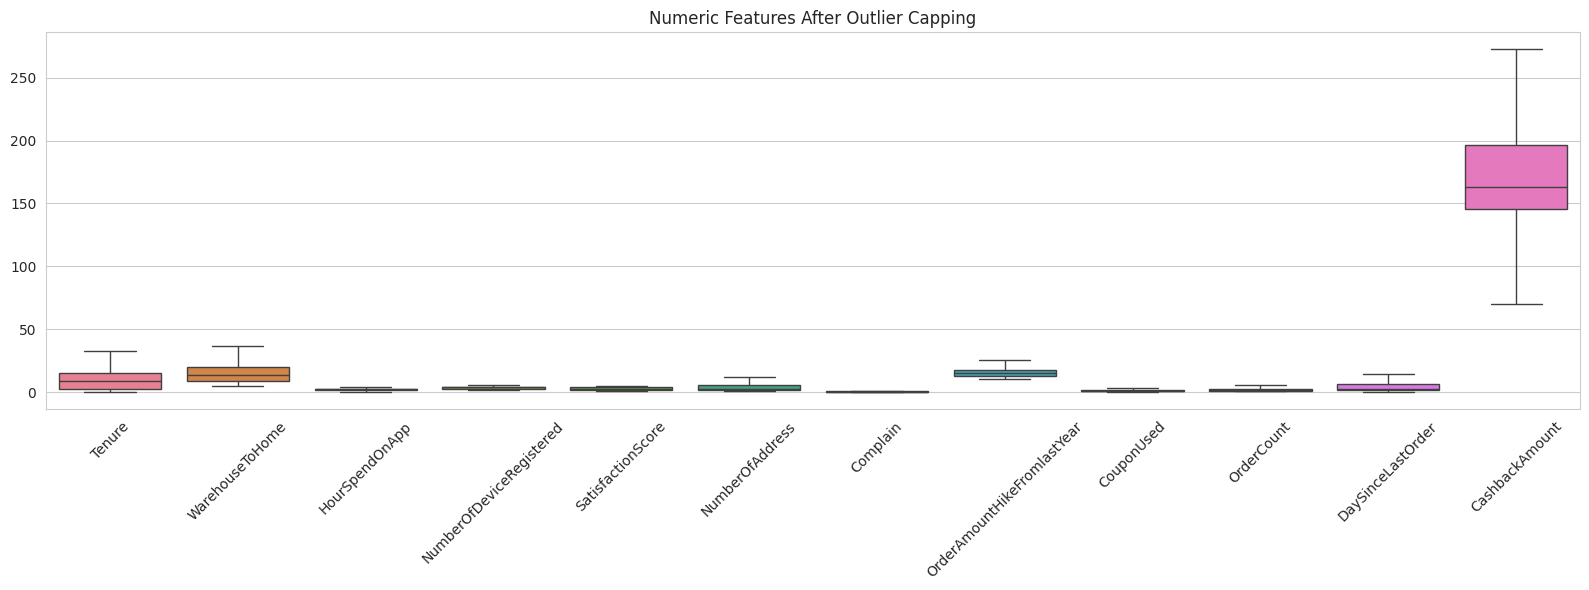

In [8]:
def iqr_bounds(col):
    q1, q3 = col.quantile(0.25), col.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in df_clean.columns:
    if is_numeric_dtype(df_clean[col]):
        lower, upper = iqr_bounds(df_clean[col])
        df_clean[col] = np.clip(df_clean[col], lower, upper)

plt.figure(figsize=(16, 6))
sns.boxplot(data=df_clean.select_dtypes(include=['int64', 'float64']))
plt.title('Numeric Features After Outlier Capping')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Feature Engineering

In [9]:
df_clean['Avg_cashbk_per_order'] = (
    df_clean['CashbackAmount'] / df_clean['OrderCount'].replace(0, np.nan)
).fillna(0)

df_clean[['CashbackAmount', 'OrderCount', 'Avg_cashbk_per_order']].head()

,CashbackAmount,OrderCount,Avg_cashbk_per_order
0,159.93,1.0,159.93
1,120.90,1.0,120.90
2,120.28,1.0,120.28
3,134.07,1.0,134.07
4,129.60,1.0,129.60


## 4. Exploratory Analysis

Overall churn rate: 16.84%


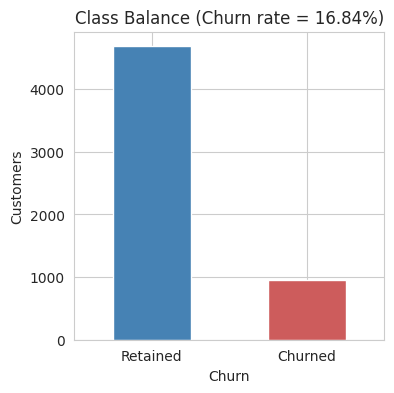

In [10]:
df_clean['Churn'] = df_clean['Churn'].astype(int)
churn_rate = round(df_clean['Churn'].mean() * 100, 2)
print(f"Overall churn rate: {churn_rate}%")

plt.figure(figsize=(4, 4))
df_clean['Churn'].value_counts().plot(kind='bar', color=['steelblue', 'indianred'])
plt.xticks([0, 1], ['Retained', 'Churned'], rotation=0)
plt.title(f'Class Balance (Churn rate = {churn_rate}%)')
plt.ylabel('Customers')
plt.show()

The classes are imbalanced — roughly 1 in 6 customers churns. We'll address this with SMOTE before modeling, and rely on precision/recall/F1/AUC rather than raw accuracy for evaluation.

In [11]:
cat_cols = [c for c in df_clean.select_dtypes(include='object').columns]
num_cols = [c for c in df_clean.select_dtypes(include=['int64', 'float64']).columns if c != 'Churn']

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['PreferredLoginDevice', 'CityTier', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
Numerical: ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount', 'Avg_cashbk_per_order']


/tmp/ipykernel_195/1845543561.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df_clean.select_dtypes(include='object').columns]


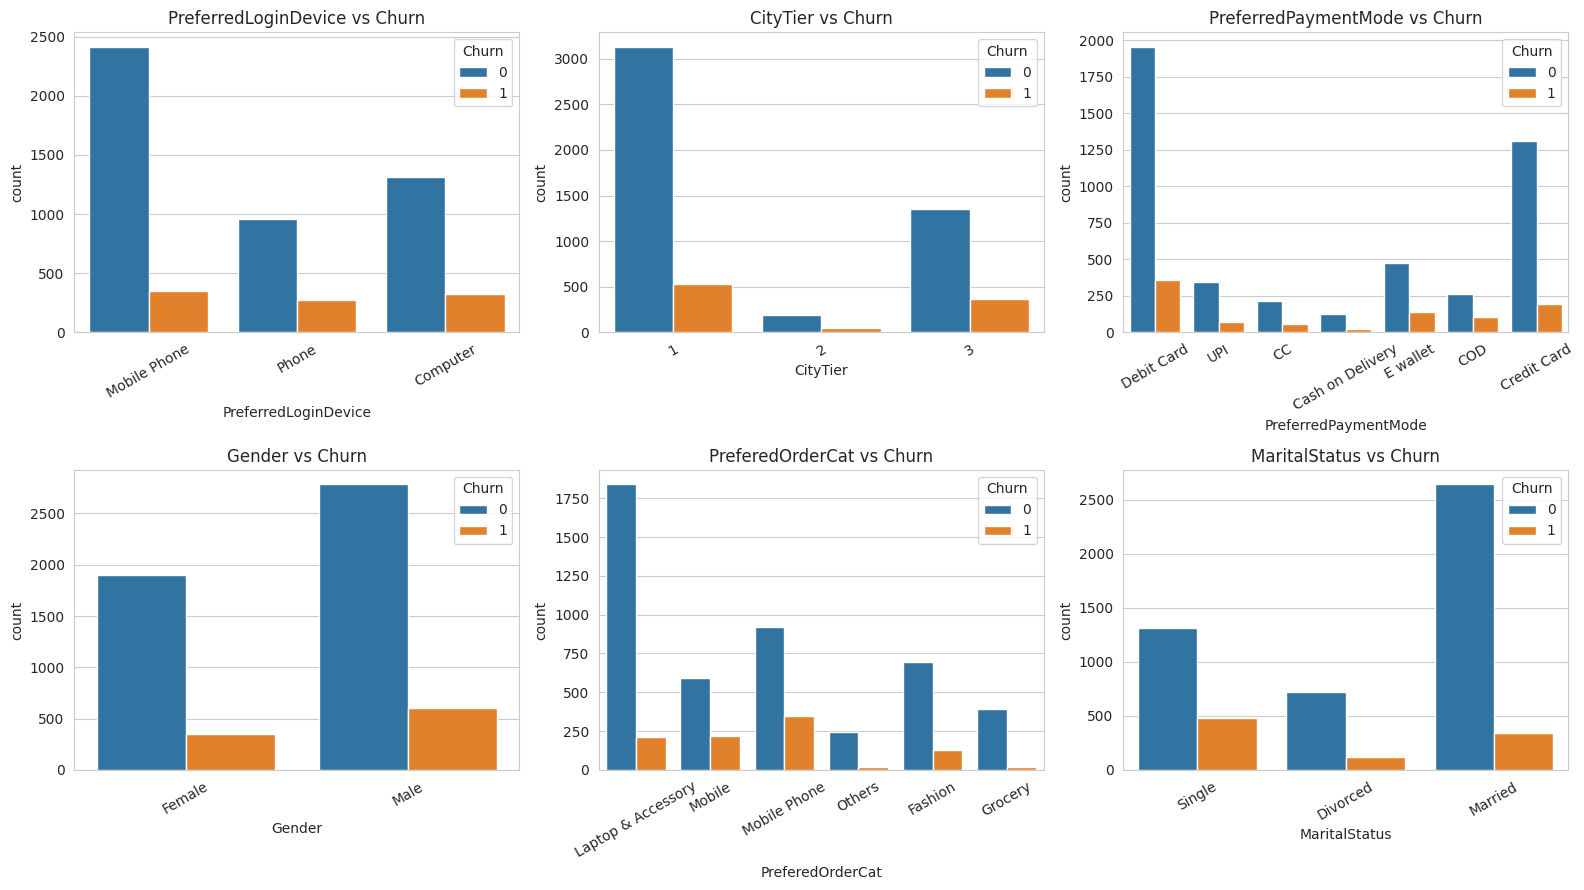

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df_clean, x=col, hue='Churn', ax=ax)
    ax.set_title(f'{col} vs Churn')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

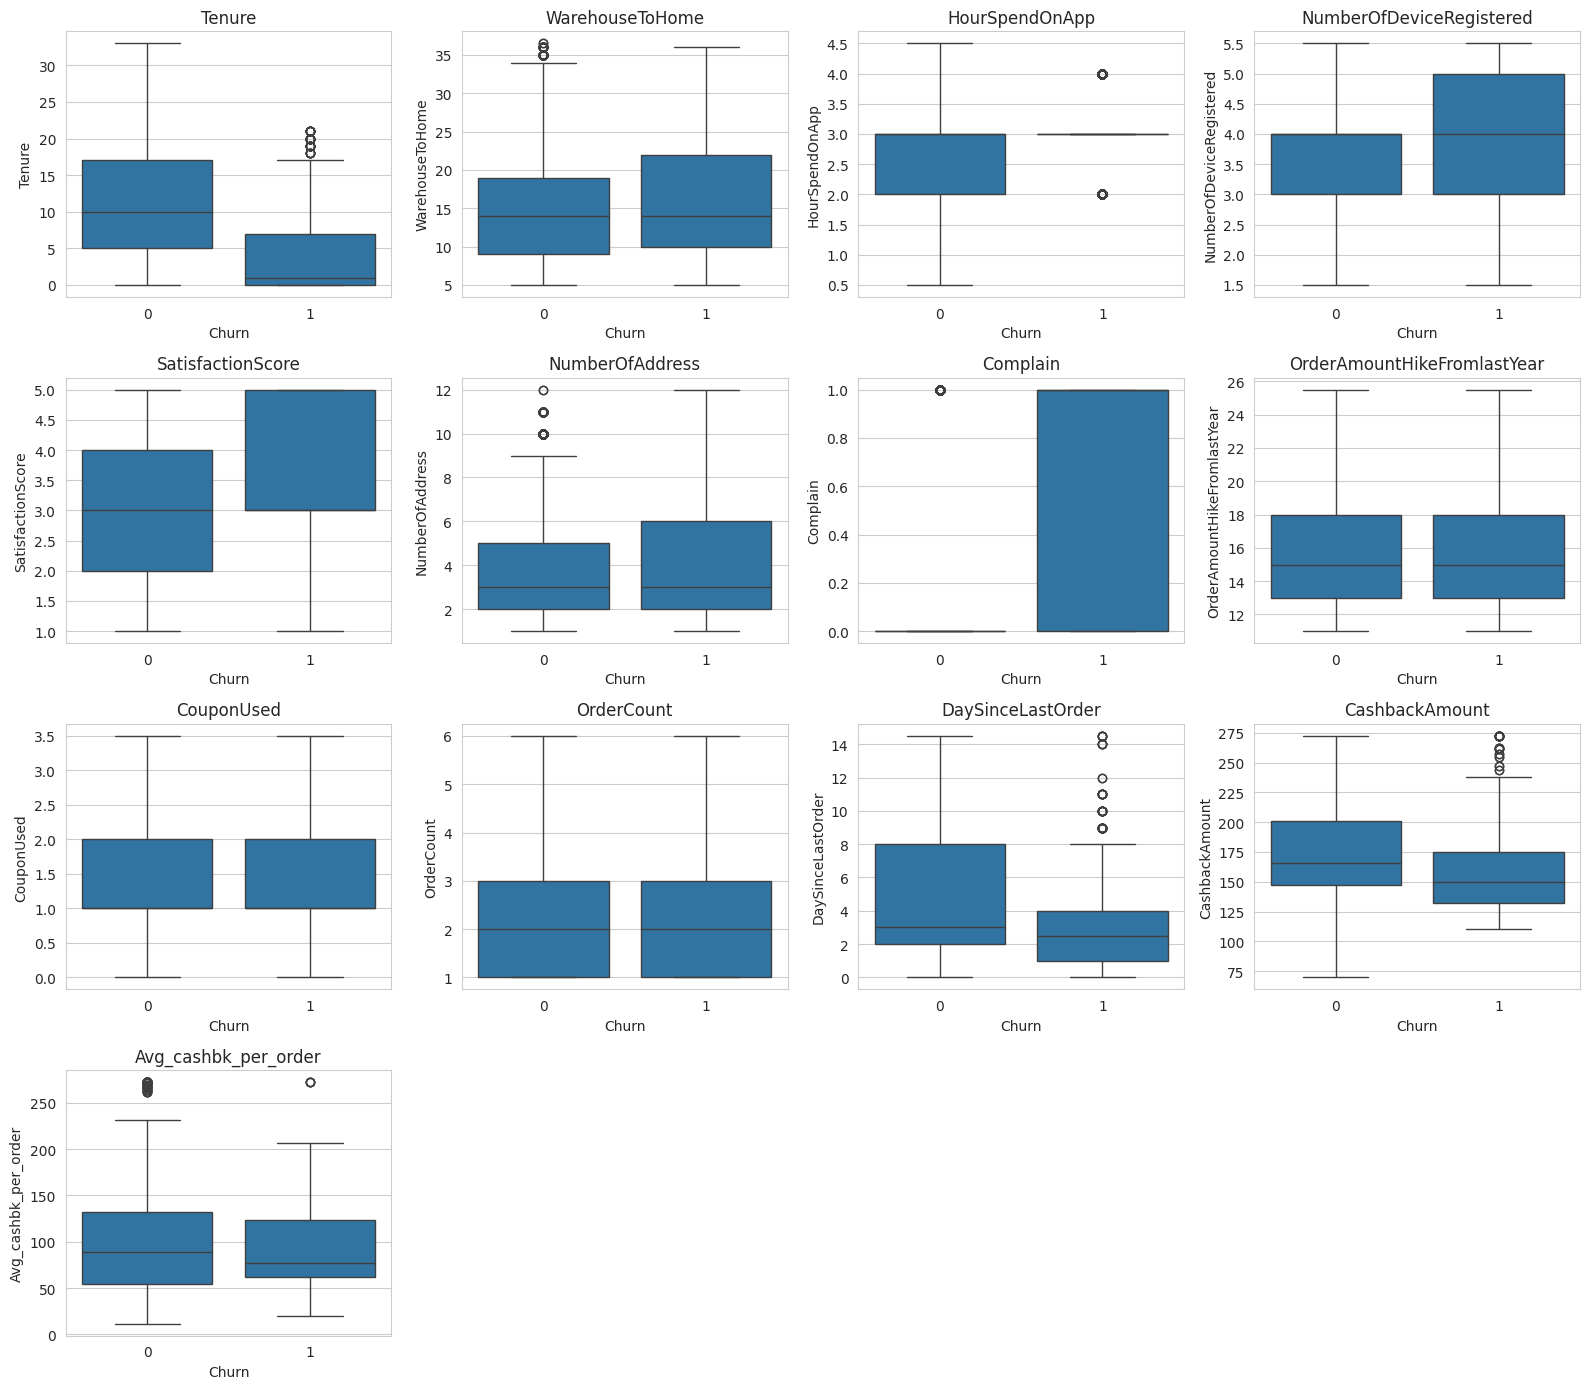

In [13]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df_clean, x='Churn', y=col, ax=ax)
    ax.set_title(col)
for ax in axes.flatten()[len(num_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Key observations:**
- Customers with **low tenure** churn far more — churn is heavily concentrated in newly acquired customers.
- **Complaints** are strongly associated with churn.
- Customers ordering via **Mobile Phone** and those in **Tier 3 cities** show somewhat higher churn.
- **Cashback amount** and **satisfaction score** relate to churn as expected: less cashback / lower satisfaction, more churn.

## 5. Encoding & Scaling

In [14]:
from sklearn.preprocessing import StandardScaler

df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)

scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

print(f"Final feature matrix shape: {df_encoded.shape}")

Final feature matrix shape: (5630, 32)


## 6. Train/Test Split & Handling Class Imbalance

In [15]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_bal.value_counts().to_dict())

Before SMOTE: {0: 3746, 1: 758}
After SMOTE:  {0: 3746, 1: 3746}


## 7. Model Training & Comparison

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

results = {}
for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    results[name] = {"model": model, "y_pred": y_pred, "y_prob": y_prob, "auc": auc}

    print(f"\n=== {name} ===")
    print(classification_report(y_test, y_pred))
    print("AUC-ROC:", round(auc, 4))


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.95      0.84      0.89       936
           1       0.49      0.77      0.60       190

    accuracy                           0.83      1126
   macro avg       0.72      0.80      0.74      1126
weighted avg       0.87      0.83      0.84      1126

AUC-ROC: 0.8677



=== Random Forest ===
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.96      0.94      0.95       190

    accuracy                           0.98      1126
   macro avg       0.98      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126

AUC-ROC: 0.997


## 8. Evaluation

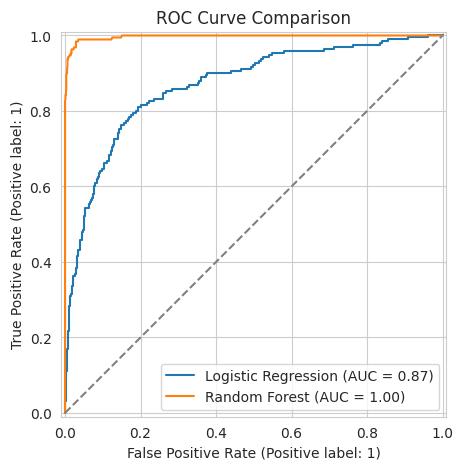

In [17]:
plt.figure(figsize=(6, 5))
for name, res in results.items():
    RocCurveDisplay.from_predictions(y_test, res['y_prob'], name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('ROC Curve Comparison')
plt.show()

Best model: Random Forest (AUC-ROC = 0.9970)


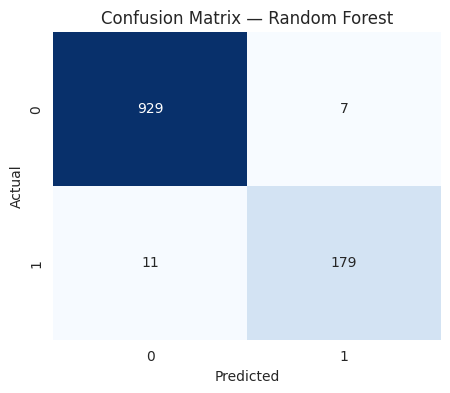

In [18]:
best_name = max(results, key=lambda k: results[k]['auc'])
best = results[best_name]
print(f"Best model: {best_name} (AUC-ROC = {best['auc']:.4f})")

cm = confusion_matrix(y_test, best['y_pred'])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix — {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 9. Feature Importance

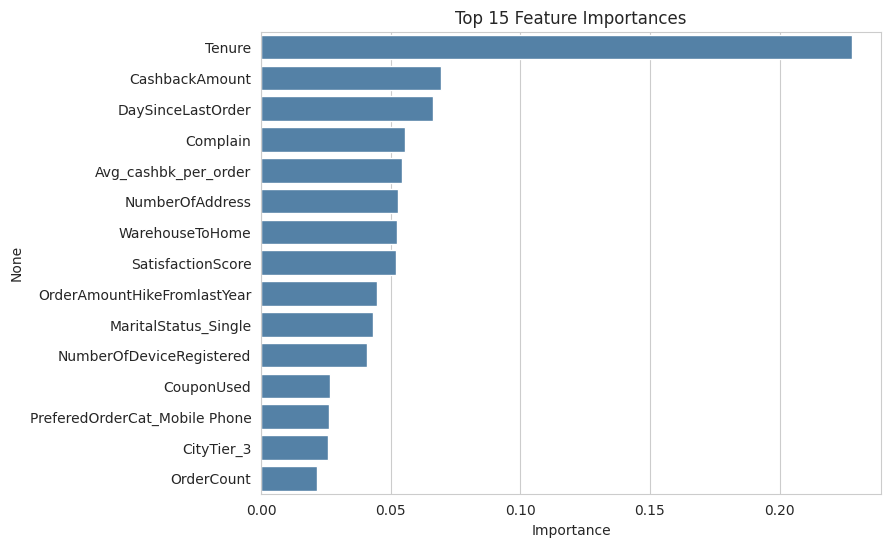

In [19]:
if hasattr(best['model'], 'feature_importances_'):
    importances = pd.Series(best['model'].feature_importances_, index=X.columns)
    top15 = importances.sort_values(ascending=False).head(15)

    plt.figure(figsize=(8, 6))
    sns.barplot(x=top15.values, y=top15.index, color='steelblue')
    plt.title('Top 15 Feature Importances')
    plt.xlabel('Importance')
    plt.show()

## 10. Conclusions & Business Recommendations

- **Tenure is the single strongest churn signal** — newer customers are far more likely to leave. Retention efforts (onboarding flows, early-lifecycle incentives) should focus on the first weeks/months of the relationship.
- **Complaints** are a strong predictor of churn — routing complaints to fast resolution paths could materially reduce churn.
- **Cashback amount and order recency** matter — customers who haven't ordered recently or are earning less cashback are at higher risk; these are good triggers for a win-back campaign.
- The **Random Forest model** substantially outperforms plain Logistic Regression on this dataset (AUC-ROC and F1 both notably higher), and is saved as the production model.

## 11. Save the Final Model

In [20]:
import joblib

joblib.dump(best['model'], '../models/churn_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(X.columns.tolist(), '../models/feature_names.pkl')

print("Model, scaler, and feature list saved to ../models/")

Model, scaler, and feature list saved to ../models/
